# 01. 저장된 결과 둘러보기 (재학습 없음)

이 노트북은 저장소에 커밋된 작은 표만 읽습니다. 서버의 원자료, Slurm, GPU가 필요하지 않습니다.

질문은 하나입니다. **유전자 전체를 남겨 둔 채 경로 방향만 덜 규제하고(soft prior), 약물 90개를 함께 학습하면 처음 보는 간암 세포 계열의 약물 민감도(AA) 예측이 좋아지는가?**

점수는 `macro nRMSE`입니다. 약물마다 예측 오차를 학습 자료의 표준편차로 나눈 뒤 평균한 값이며, **낮을수록 좋습니다.** 학습 평균만 내놓는 예측이 대략 1.05입니다. 같은 자료의 결과가 연구 A에서 이미 공개되었으므로, 아래 숫자는 '동결 뒤 재사용 공개 벤치마크 평가'이지 처음 보는 자료에서의 검증이 아닙니다.

In [1]:
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "configs", "softprior_multitask_r1")):
    parent = os.path.dirname(root)
    assert parent != root, "저장소 안에서 실행해 주세요."
    root = parent
sys.path.insert(0, os.path.join(root, "src", "softprior_multitask_r1"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
T = os.path.join(root, "reports", "softprior_multitask_r1", "tables")
print("결과표 폴더를 찾았습니다:", os.path.isdir(T))

결과표 폴더를 찾았습니다: True


## 1. 최종 비교표

행 하나가 모델 하나입니다. 구간은 계열(환자) 76개를 다시 뽑아 만든 95% 구간입니다. 세 번의 반복 점수와, 반복을 평균한 예측의 점수(`ensemble`)를 따로 적었습니다.

In [2]:
summ = pd.read_csv(os.path.join(T, "final_internal_summary.tsv"), sep="\t")
cols = ["model", "macro_drug_normalized_rmse", "ci_low", "ci_high", "repeat0", "repeat1", "repeat2", "ensemble_of_repeats_macro_nrmse", "mean_spearman"]
print(summ[cols].round(4).to_string(index=False))

     model  macro_drug_normalized_rmse  ci_low  ci_high  repeat0  repeat1  repeat2  ensemble_of_repeats_macro_nrmse  mean_spearman
        A0                      1.0537  0.9576   1.1430   1.0472   1.0602   1.0536                           1.0163        -0.1867
        A1                      1.0127  0.9245   1.0885   1.0490   0.9898   0.9992                           0.9618         0.2991
       A1r                      0.9917  0.9034   1.0721   0.9898   0.9886   0.9966                           0.9506         0.3023
        A3                      1.0353  0.9347   1.1276   1.0256   1.0333   1.0470                           0.9883         0.1754
      enet                      1.3546  1.0723   1.5414   1.6302   1.2316   1.2020                           1.2424         0.1189
    cwkbmf                      0.9961  0.9043   1.0841   0.9931   0.9953   0.9998                           0.9586         0.2776
    tabpfn                      1.0246  0.9288   1.1138   1.0199   1.0280   1.0261 

모델 이름:

- `A0` 학습 평균, `A1` 유전자 log2 Ridge, `A1r` 유전자 순위 Ridge, `A3` Hallmark 점수 50개 Ridge — 연구 A의 방법 그대로(유전자 축만 고침)
- `enet` raw RNA ElasticNet, `cwkbmf`·`tabpfn` 공개 방법(실행된 경우에만 행이 있습니다)
- `ridge_pd` / `ridge_gl` 유전자 순위 Ridge, 규제 강도를 약물마다 / 모든 약물에 하나
- `par_pd` / `par_gl` 경로 부분공간만 쓰는 hard prior
- `soft_pd` / `soft_gl` soft prior(경로 밖 방향을 더 세게 규제), 약물 공유 없음
- `mt_noprior` prior 없는 다중약물 공유, `full` 처음의 통합 설계
- `mt_resid` 공유 low-rank + 약물별 Ridge 잔차(prior 없음), `full_resid` 같은 구조에 soft prior를 더한 **최종 통합 모델**

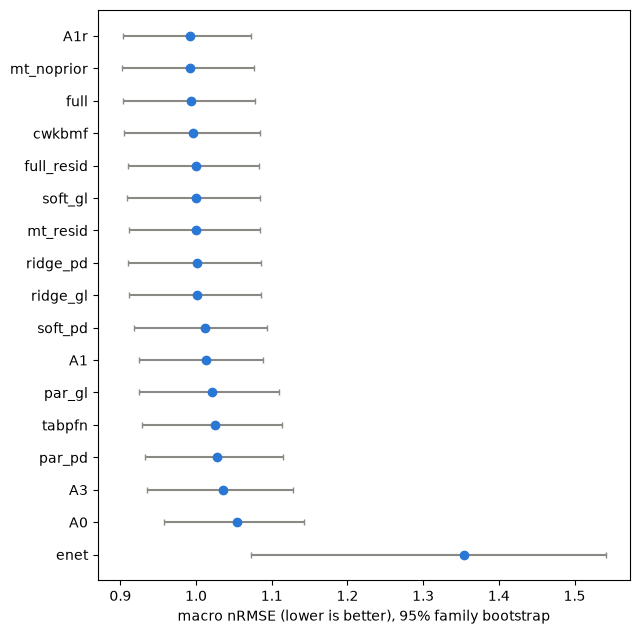

In [3]:
order = summ.sort_values("macro_drug_normalized_rmse")
fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(order) + 1))
y = np.arange(len(order))[::-1]
ax.errorbar(order.macro_drug_normalized_rmse, y, xerr=[order.macro_drug_normalized_rmse - order.ci_low, order.ci_high - order.macro_drug_normalized_rmse], fmt="o", color="#2a78d6", ecolor="#8a8983", capsize=2)
ax.set_yticks(y); ax.set_yticklabels(order.model); ax.set_xlabel("macro nRMSE (lower is better), 95% family bootstrap")
plt.tight_layout(); plt.show()

구간이 서로 크게 겹칩니다. 그래서 모델 둘을 비교할 때는 **같은 계열에서의 차이**를 다시 뽑아 구간을 만듭니다(짝지은 비교). 차이의 구간이 0을 포함하면 '다르다고 말할 수 없다'입니다.

In [4]:
diff = pd.read_csv(os.path.join(T, "final_internal_differences.tsv"), sep="\t")
print(diff.round(4).to_string(index=False))

     model reference  difference  ci_low  ci_high  boot_fraction_below_zero  drugs_model_better  drugs_reference_better  n_drugs
full_resid        A0     -0.0538 -0.0793  -0.0261                    0.9995                  71                      19       90
full_resid  ridge_pd     -0.0010 -0.0040   0.0021                    0.7600                  51                      39       90
full_resid       A1r      0.0082  0.0024   0.0133                    0.0035                  23                      67       90
full_resid        A3     -0.0354 -0.0510  -0.0176                    1.0000                  75                      15       90
full_resid    par_pd     -0.0281 -0.0415  -0.0135                    1.0000                  70                      20       90
full_resid  mt_resid     -0.0002 -0.0016   0.0013                    0.6550                  48                      42       90
full_resid   soft_pd     -0.0116 -0.0211  -0.0036                    1.0000                  74  

## 2. 실제 경로와 무작위 경로

유전자 이름표를 통째로 섞어 만든 무작위 '경로' 20벌로 같은 절차를 반복했습니다. 실제 Hallmark 구성이 의미가 있다면 실제 prior의 점수가 무작위 20개보다 낮아야 합니다.

     model    real  perm_mean  perm_sd  perm_min  perm_max  n_perm  n_perm_at_or_below_real  real_minus_perm_mean   ci_low  ci_high
full_resid 0.99989    0.99929  0.00002   0.99928   0.99932      20                       20               0.00060 -0.00074  0.00188
   soft_pd 1.01149    1.00336  0.00244   0.99707   1.00641      20                       20               0.00813 -0.00022  0.01795
    par_pd 1.02794    1.03844  0.00665   1.02234   1.04800      20                        2              -0.01050 -0.02657  0.00871


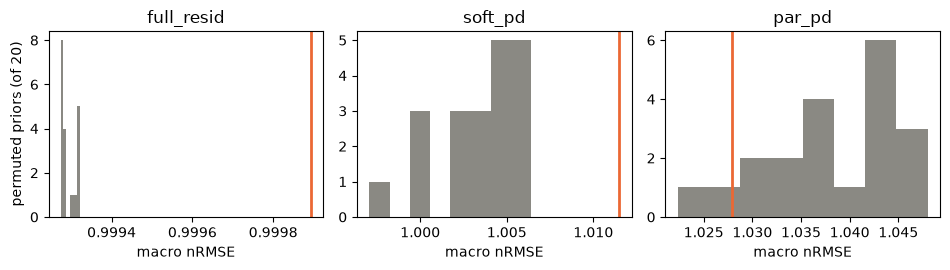

주황 선 = 실제 Hallmark prior


In [5]:
rp = pd.read_csv(os.path.join(T, "final_internal_real_vs_permuted_prior.tsv"), sep="\t")
print(rp.round(5).to_string(index=False))
ps = pd.read_csv(os.path.join(T, "final_internal_permuted_prior_scores.tsv"), sep="\t")
fig, axes = plt.subplots(1, len(rp), figsize=(3.2 * len(rp), 2.8))
for ax, (_, r) in zip(np.atleast_1d(axes), rp.iterrows()):
    v = ps[ps.model == r.model].macro_drug_normalized_rmse
    ax.hist(v, bins=8, color="#8a8983"); ax.axvline(r.real, color="#eb6834", lw=2)
    ax.set_title(r.model); ax.set_xlabel("macro nRMSE")
axes[0].set_ylabel("permuted priors (of 20)"); plt.tight_layout(); plt.show()
print("주황 선 = 실제 Hallmark prior")

## 3. 각 모델이 실제로 고른 설정

설정 이름은 `ridge|종류|λ`, `nuc|η/λ|λ|τ비율`, `res|η/λ|λ|τ비율|λ₂`입니다. η/λ가 0이면 prior를 쓰지 않은 것이고, τ비율이 클수록 약물 사이 공유가 강합니다(해의 rank가 낮습니다).

In [6]:
ch = pd.read_csv(os.path.join(T, "final_internal_chosen.tsv"), sep="\t")
for m in ["soft_gl", "mt_noprior", "full_resid"]:
    print(m); print(ch[ch.model == m].head(6).to_string(index=False)); print()
fr = ch[ch.model == "full_resid"].copy()
fr["eta_over_lambda"] = fr.config.str.split("|").str[1]
print("full_resid에서 선택된 η/λ의 비율:"); print(fr.groupby("eta_over_lambda").fraction.sum().round(3))

soft_gl
  model           config  n_chosen  fraction
soft_gl     ridge|r1|1.0       630   0.46670
soft_gl    ridge|r10|1.0       360   0.26670
soft_gl ridge|whole|10.0       180   0.13330
soft_gl  ridge|whole|1.0        90   0.06667
soft_gl    ridge|r10|0.1        90   0.06667

mt_noprior
     model             config  n_chosen  fraction
mt_noprior    nuc|0.0|1.0|0.1       540    0.4000
mt_noprior nuc|0.0|0.0001|0.1       450    0.3333
mt_noprior   ridge|whole|10.0       180    0.1333
mt_noprior    nuc|0.0|0.1|0.1       180    0.1333

full_resid
     model                    config  n_chosen  fraction
full_resid    res|100.0|1.0|0.1|10.0       141   0.10440
full_resid res|0.0|0.0001|0.3|0.0001       134   0.09926
full_resid   res|0.0|0.0001|0.3|10.0       125   0.09259
full_resid    res|0.0|0.0001|0.3|inf       122   0.09037
full_resid    res|0.0|0.0001|0.3|1.0        97   0.07185
full_resid     res|100.0|1.0|0.1|1.0        82   0.06074

full_resid에서 선택된 η/λ의 비율:
eta_over_lambda
0.0   

## 4. 약물 90개를 함께 학습해도 표본이 90배가 되지 않는 이유

행렬은 79 × 90 = 7,110칸이지만 서로 독립인 것은 계열 76개입니다. 약물 90개의 값은 같은 세포에서 나왔고 서로 상관되어 있습니다. 아래 표는 학습 계열에서 구한 '약물 공통 성분'이 보지 않은 계열의 분산을 얼마나 설명하는지입니다(개발 구간에서 계산). 첫 성분 하나가 약 30%를 차지합니다. 즉 약물 90개는 90개의 독립된 문제가 아니라 상당 부분 같은 문제의 반복입니다.

In [7]:
d2 = pd.read_csv(os.path.join(T, "d2_heldout_subspace.tsv"), sep="\t")
print(d2.round(4).to_string(index=False))

 k  heldout_share_mean  heldout_share_min  permuted_columns_null_mean  permuted_columns_null_min  random_expectation_mean  random_expectation_min
 1              0.2973             0.2038                      0.0117                     0.0084                   0.0111                  0.0111
 2              0.3319             0.2312                      0.0228                     0.0185                   0.0222                  0.0222
 3              0.3618             0.2568                      0.0341                     0.0279                   0.0333                  0.0333
 5              0.4098             0.2975                      0.0562                     0.0504                   0.0556                  0.0556
10              0.4956             0.3763                      0.1112                     0.1003                   0.1111                  0.1111
20              0.6158             0.5376                      0.2237                     0.2137                   0.2222   

약물을 늘려도 구간의 폭은 계열 수가 정합니다. 최종표에서 어느 모델이든 구간의 폭이 약 0.18인 것이 그 결과입니다.

In [8]:
print((summ.ci_high - summ.ci_low).round(3).describe()[["min", "max"]])

min    0.164
max    0.469
dtype: float64


## 5. 전반적 민감도와 약물 선호도

각 세포의 예측과 실측에서 **각자의** 약물 평균을 뺍니다. 평균은 '이 세포가 전반적으로 약에 잘 듣는가', 나머지는 '어떤 약에 상대적으로 더 잘 듣는가'입니다. 두 부분의 일치도를 따로 봅니다.

In [9]:
pref = pd.read_csv(os.path.join(T, "final_internal_broad_vs_preference.tsv"), sep="\t")
print(pref.round(4).to_string(index=False))

     model  broad_sensitivity_spearman  preference_within_cell_spearman  preference_per_drug_spearman  broad_mse  preference_mse
        A0                     -0.0030                          -0.0035                       -0.0083     0.3326          0.7807
        A1                      0.4860                           0.2542                        0.2324     0.2671          0.7709
       A1r                      0.5078                           0.2624                        0.2414     0.2590          0.7332
        A3                      0.4362                           0.1815                        0.1335     0.2898          0.7892
      enet                      0.3984                           0.1774                        0.1415     0.3883          4.1681
    cwkbmf                      0.4774                           0.2606                        0.2430     0.2712          0.7271
    tabpfn                      0.4260                           0.1842                        0.

## 6. 외부 자료(LCCL)

LCCL은 다른 연구가 다른 지표(AUC)로 잰 자료입니다. 값을 합치지 않고, 약물마다 예측 순위와 실측 순위의 일치도(Spearman)만 봅니다. `cross_study_leave_family_out`은 LIMORE에도 있는 계열(해당 계열은 학습에서 뺌), `new_lineage`는 LIMORE에 없는 계열 4개입니다. 4개 계열로는 요약 통계가 의미를 갖기 어렵습니다.

In [10]:
ex = pd.read_csv(os.path.join(T, "final_external_summary.tsv"), sep="\t")
print(ex[ex.endpoint == "AUC"].round(3).to_string(index=False))
print(pd.read_csv(os.path.join(T, "final_external_differences.tsv"), sep="\t").query("endpoint == 'AUC'").round(3).to_string(index=False))

     model                    eval_type endpoint  n_families  n_models  n_drugs_scored  mean_spearman  median_spearman  ci_low  ci_high  n_drugs_positive
       A1r cross_study_leave_family_out      AUC          26        27              18          0.237            0.286   0.106    0.356                15
       A1r                  new_lineage      AUC           4         5              18          0.101            0.100  -0.222    0.333                 9
        A3 cross_study_leave_family_out      AUC          26        27              18          0.004            0.084  -0.158    0.165                10
        A3                  new_lineage      AUC           4         5              18          0.066            0.053  -0.333    0.667                 9
  ridge_pd cross_study_leave_family_out      AUC          26        27              18          0.208            0.279   0.078    0.328                14
  ridge_pd                  new_lineage      AUC           4         5      

## 7. 실행하지 못한 비교군

비어 있으면 모두 실행된 것입니다.

In [11]:
print(pd.read_csv(os.path.join(T, "final_not_run.tsv"), sep="\t").to_string(index=False))

Empty DataFrame
Columns: [model, part, reason]
Index: []
